## Setup

In [1]:
import re
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from nltk import NaiveBayesClassifier, FreqDist
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dustin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [2]:
# formats all floats to two decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
# formats all floats to two decimal places
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## Import Data

In [4]:
df = pd.read_csv("IMDB-Dataset.csv")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
LABELS = ["negative", "neutral", "positive"]   # VADER / TextBlob can output all three
HUMAN_LABELS = ["negative", "positive"]        # the human labels only have these two

## EDA

### Basic Inspection

In [6]:
# create a copy of original dataset
imdb_df = df.copy()

In [7]:
imdb_df.shape

(50000, 2)

In [8]:
imdb_df.columns

Index(['review', 'sentiment'], dtype='object')

In [9]:
imdb_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [10]:
imdb_df.isna().sum()   # no missing data

review       0
sentiment    0
dtype: int64

In [11]:
imdb_df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


### Clean Review Column

In [12]:
def clean_review(text):
    """
    Light-touch cleaning of an IMDB review for VADER / TextBlob.
    Removes noise (HTML, URLs, mentions, etc.) but keeps the signal
    VADER relies on: capitalization, punctuation like '!' and '?',
    and emoticons.
    """
    if not isinstance(text, str):
        return ""

    # Decode HTML entities (e.g. &amp; -> &, &quot; -> ")
    text = html.unescape(text)

    # Remove HTML tags such as <br /> or <i>
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove URLs (http, https, www)
    text = re.sub(r"(https?://\S+|www\.\S+)", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+\.\S+", " ", text)

    # Remove @mentions and #hashtags
    text = re.sub(r"[@#]\w+", " ", text)

    # Remove characters that aren't letters, digits, whitespace,
    # or sentiment-relevant punctuation (! ? . , ' : ; ( ) -)
    text = re.sub(r"[^A-Za-z0-9\s!?.,':;()\-]", " ", text)

    # Collapse repeated whitespace and trim
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [13]:
imdb_df["clean_review"] = imdb_df["review"].apply(clean_review)

In [14]:
imdb_df[["review", "clean_review"]].sample(15)

,review,clean_review
13884,Let's eliminate any discussion about the use o...,Let's eliminate any discussion about the use o...
42539,I have always admired Susan Sarandon for her i...,I have always admired Susan Sarandon for her i...
10627,I watched this film because I noticed that it ...,I watched this film because I noticed that it ...
34195,This film is about a man who has been too caug...,This film is about a man who has been too caug...
32045,The book is great. It's one of my favorite boo...,The book is great. It's one of my favorite boo...
11170,"""Creepshow 2"" is little more than a pale imita...",Creepshow 2 is little more than a pale imitati...
32040,"Solid comedy entertainment, with musical inter...","Solid comedy entertainment, with musical inter..."
49068,I've been watching Attack Of The Show religiou...,I've been watching Attack Of The Show religiou...
8130,When you look back at another bad Nightmare se...,When you look back at another bad Nightmare se...
46934,Normally I'm quite disposed to like low budget...,Normally I'm quite disposed to like low budget...


### Bar Chart

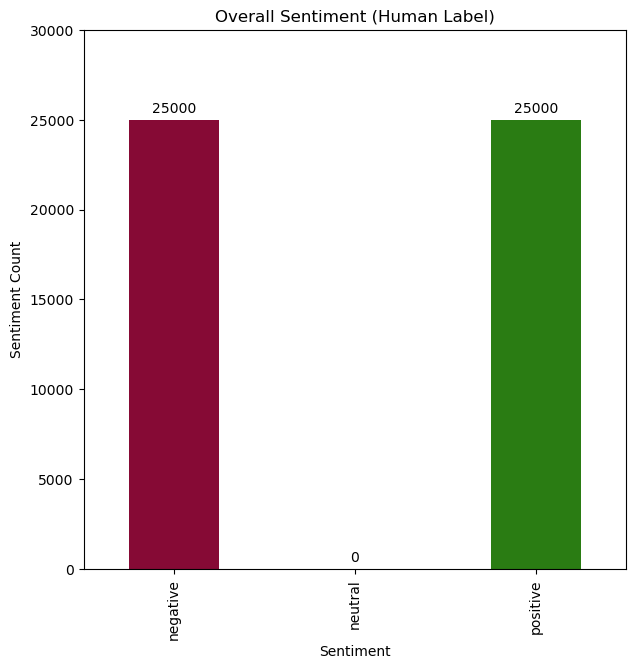

In [15]:
sentiment_count = imdb_df['sentiment'].value_counts().reindex(LABELS).sort_index().plot(
    figsize=(7,7),
    kind='bar',
    color=['#860A35', '#F3F3F3', '#2A7C13'],
    title='Overall Sentiment (Human Label)',
    xlabel='Sentiment',
    ylabel='Sentiment Count')

# Add the total count at the top of each bar
sentiment_count.bar_label(sentiment_count.containers[0], fmt='%d', padding=3)

# Leave a little headroom so the labels don't get clipped
sentiment_count.margins(y=0.2)

plt.show()

### Word Cloud

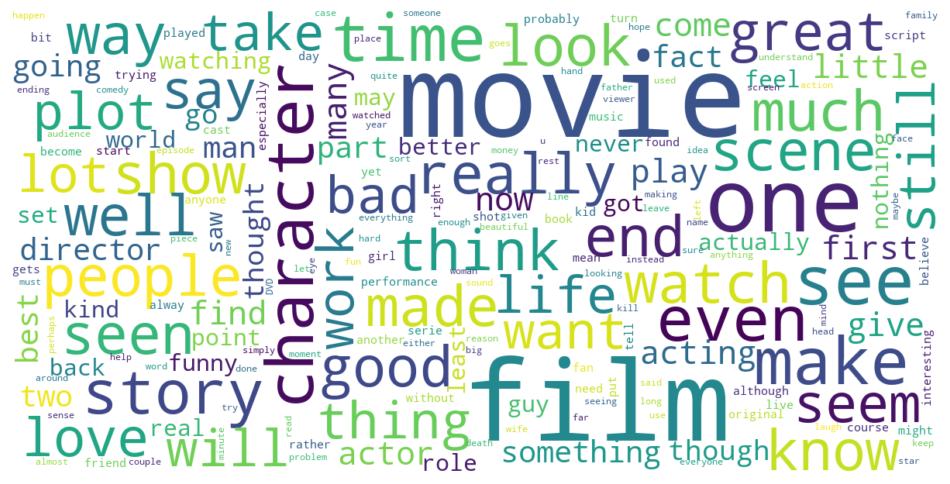

In [16]:
reviews = imdb_df['clean_review'].str.cat(sep=" ")

wordcloud = WordCloud(
    background_color = 'white',
    stopwords = STOPWORDS,
    max_words = 200,
    max_font_size = 50,
    scale = 3,
    random_state = 1
).generate(reviews)

plt.figure(figsize=(12,12))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

## Train/Test Split

In [17]:
train, test = train_test_split(imdb_df, test_size=0.2, random_state=42,
                               stratify=imdb_df["sentiment"])

y_train = train['sentiment'].to_numpy()
y_test = test['sentiment'].to_numpy()

print(len(train), 'train data; ', len(test), 'test data')

results, preds = {}, {}

40000 train data;  10000 test data


In [18]:
def evaluate(name, y_pred, labels=HUMAN_LABELS):
    """Stores scores, prints the classification report, and plots the confusion matrix.
    Pass labels=LABELS for models that can predict 'neutral' (VADER, TextBlob)."""
    y_pred = np.asarray(y_pred)
    preds[name] = y_pred

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        # macro F1 over the two human classes only (neutral has no true samples)
        "macro_f1": f1_score(y_test, y_pred, labels=HUMAN_LABELS, average="macro")
    }

    print(f"==={name}===")
    print(classification_report(y_test, y_pred, labels=labels, digits=3, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels, cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.show()

## VADER Model

In [19]:
vader = SentimentIntensityAnalyzer()

In [20]:
def vader_label(text, threshold=0.2):
    c = vader.polarity_scores(text)['compound']

    if c >= threshold:
        return "positive"
    elif c <= -threshold:
        return "negative"
    else:
        return "neutral"

===VADER===
              precision    recall  f1-score   support

    negative      0.803     0.512     0.626      5000
     neutral      0.000     0.000     0.000         0
    positive      0.657     0.854     0.742      5000

    accuracy                          0.683     10000
   macro avg      0.487     0.455     0.456     10000
weighted avg      0.730     0.683     0.684     10000



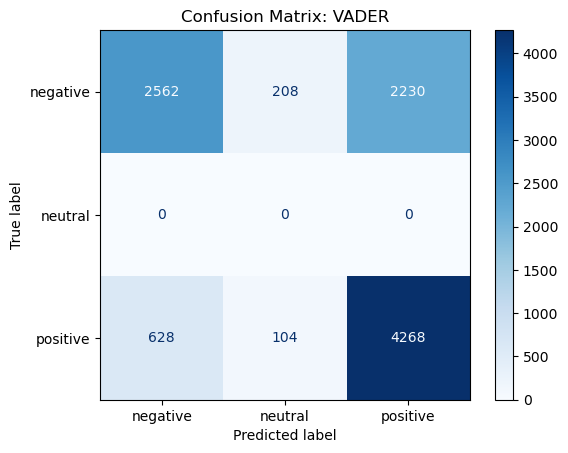

In [21]:
evaluate("VADER", test['clean_review'].apply(vader_label), labels=LABELS)

## NLTK + Naive Bayes Model

In [22]:
# Tokenizer and stopwords
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

KEEP = {"no", "nor", "not", "very", "too", "against"}
STOP = {w for w in stopwords.words("english") if w not in KEEP and "n't" not in w}

def review_tokens(text):
    toks = tokenizer.tokenize(text)
    toks = mark_negation(toks)
    return [t for t in toks
            if t.replace("_NEG", "") not in STOP and re.search(r"\w", t)]

print(review_tokens("I do NOT like this movie, the plot was too long!!!"))

['not', 'like_NEG', 'movie_NEG', ',_NEG', 'plot_NEG', 'too_NEG', 'long_NEG']


In [23]:
train_tokens = [review_tokens(t) for t in train['clean_review']]
test_tokens = [review_tokens(t) for t in test['clean_review']]

freq = FreqDist(w for toks in train_tokens for w in toks)
VOCAB = {w for w, _ in freq.most_common(3000)}

def nltk_features(tokens):
    return {w: True for w in set(tokens) if w in VOCAB}  # bag-of-words

train_set = [(nltk_features(t), y) for t, y in zip(train_tokens, y_train)]

nb = NaiveBayesClassifier.train(train_set)
nb.show_most_informative_features(20)

Most Informative Features
                   waste = True           negati : positi =     14.8 : 1.0
               waste_NEG = True           negati : positi =     13.8 : 1.0
                  seagal = True           negati : positi =     12.1 : 1.0
               redeeming = True           negati : positi =     12.0 : 1.0
                 unfunny = True           negati : positi =     11.8 : 1.0
                  insult = True           negati : positi =     10.5 : 1.0
                   awful = True           negati : positi =     10.2 : 1.0
              amateurish = True           negati : positi =     10.0 : 1.0
               atrocious = True           negati : positi =      9.9 : 1.0
                  poorly = True           negati : positi =      9.8 : 1.0
               laughable = True           negati : positi =      9.7 : 1.0
                   worst = True           negati : positi =      9.7 : 1.0
                  wasted = True           negati : positi =      8.5 : 1.0

===NLTK + Naive Bayes===
              precision    recall  f1-score   support

    negative      0.798     0.894     0.843      5000
    positive      0.879     0.773     0.823      5000

    accuracy                          0.833     10000
   macro avg      0.838     0.833     0.833     10000
weighted avg      0.838     0.833     0.833     10000



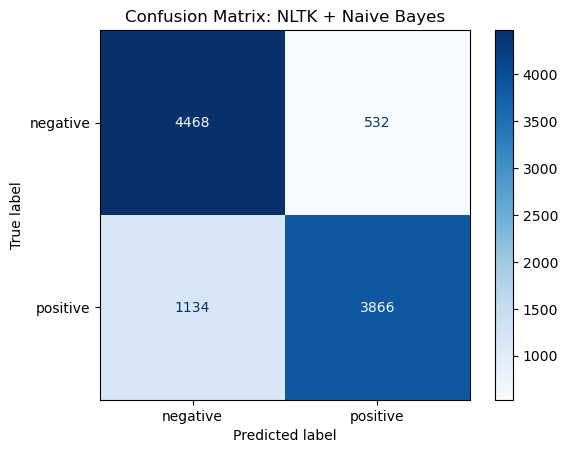

In [24]:
evaluate("NLTK + Naive Bayes", [nb.classify(nltk_features(t)) for t in test_tokens])

In [25]:
results

{'VADER': {'accuracy': 0.683, 'macro_f1': 0.6840155032536317},
 'NLTK + Naive Bayes': {'accuracy': 0.8334, 'macro_f1': 0.8327940389087669}}